# Country Development Clustering using K-means and DBSCAN
**Team:** Nexus Innovators | **Course:** Beginner Machine Learning Project, CSE 12th Batch, CCN University of Science & Technology

**Goal:** group 167 countries by development level using nine socio-economic and health indicators, and compare **K-means** with **DBSCAN**.

**Dataset:** Country Development ("Unsupervised Learning on Country Data"), Kaggle: https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data

**How to run in Google Colab:** click *Runtime → Run all*. When the data-loading cell asks, upload `Country-data.csv`.

## 1. Import libraries

In [1]:
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
import sklearn

RS = 42  # random state for reproducibility
plt.rcParams.update({"font.size": 9, "figure.dpi": 110})
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


## 2. Load the dataset
In Colab, the cell asks you to upload `Country-data.csv`. If the file is already in the working folder, it is used directly.

In [2]:
import os
if not os.path.exists("Country-data.csv"):
    try:
        from google.colab import files
        print("Please upload Country-data.csv")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Put Country-data.csv in the same folder as this notebook.")

df = pd.read_csv("Country-data.csv")
feats = [c for c in df.columns if c != "country"]
df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


## 3. Data inspection
We check size, data types, missing values, duplicates, skewness and outliers (1.5×IQR rule).

In [3]:
print("Shape (rows, columns):", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()), "| Duplicate country names:", int(df.country.duplicated().sum()))
print()
df.info()

Shape (rows, columns): (167, 10)
Missing values: 0
Duplicate rows: 0 | Duplicate country names: 0

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB


In [4]:
summary = df[feats].describe().T.round(2)
summary["skew"] = df[feats].skew().round(2)
q1, q3 = df[feats].quantile(.25), df[feats].quantile(.75); iqr = q3 - q1
summary["IQR_outliers"] = ((df[feats] < q1 - 1.5*iqr) | (df[feats] > q3 + 1.5*iqr)).sum()
summary

,count,mean,std,min,25%,50%,75%,max,skew,IQR_outliers
child_mort,167.0,38.27,40.33,2.60,8.25,19.30,62.10,208.00,1.45,4
exports,167.0,41.11,27.41,0.11,23.80,35.00,51.35,200.00,2.45,5
health,167.0,6.82,2.75,1.81,4.92,6.32,8.60,17.90,0.71,2
imports,167.0,46.89,24.21,0.07,30.20,43.30,58.75,174.00,1.91,4
income,167.0,17144.69,19278.07,609.00,3355.00,9960.00,22800.00,125000.00,2.23,8
inflation,167.0,7.78,10.57,-4.21,1.81,5.39,10.75,104.00,5.15,5
life_expec,167.0,70.56,8.89,32.10,65.30,73.10,76.80,82.80,-0.97,3
total_fer,167.0,2.95,1.51,1.15,1.80,2.41,3.88,7.49,0.97,1
gdpp,167.0,12964.16,18328.70,231.00,1330.00,4660.00,14050.00,105000.00,2.22,25


## 4. Exploratory data analysis

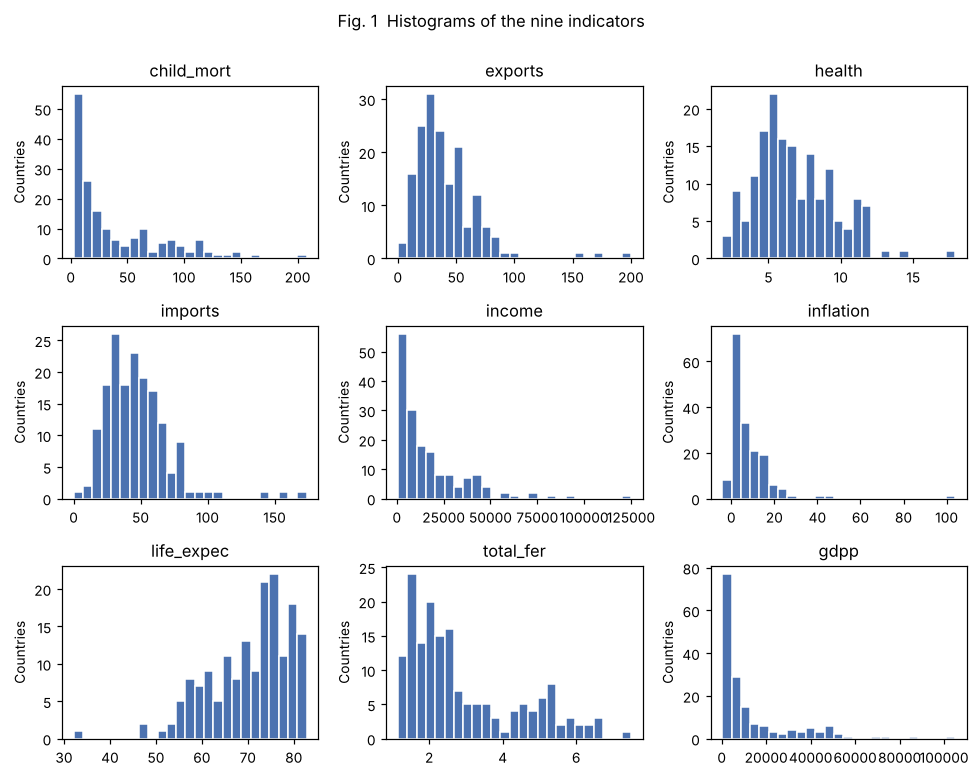

In [5]:
fig, ax = plt.subplots(3, 3, figsize=(9, 7))
for a, c in zip(ax.ravel(), feats):
    a.hist(df[c], bins=25, color="#4C72B0", edgecolor="white"); a.set_title(c); a.set_ylabel("Countries")
plt.suptitle("Fig. 1  Histograms of the nine indicators", y=1.0)
plt.tight_layout(); plt.show()

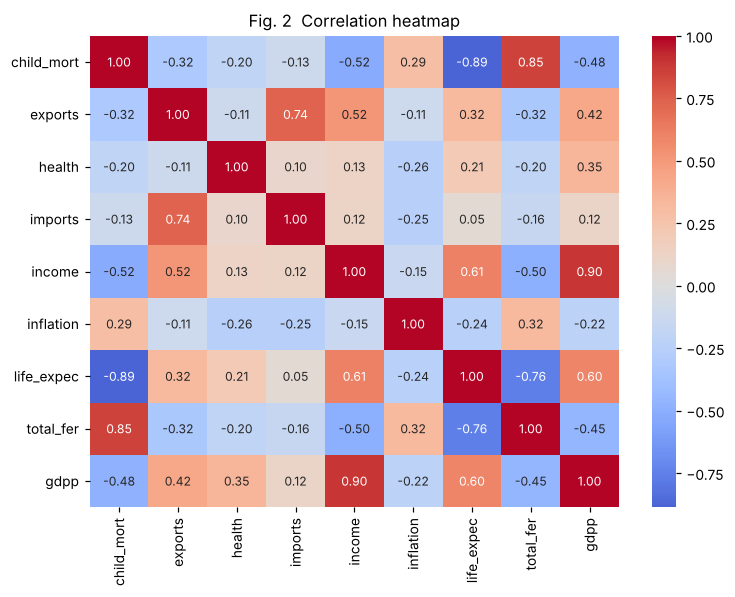

In [6]:
corr = df[feats].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Fig. 2  Correlation heatmap"); plt.tight_layout(); plt.show()

**Interpretation:** most indicators are right-skewed (income, GDP per capita, exports, imports, inflation). Child mortality is strongly negatively correlated with life expectancy and positively with fertility; income and GDP per capita are highly correlated. Outliers are real countries, so they are kept.

## 5. Preprocessing: standardisation
K-means and DBSCAN use Euclidean distance, so features are scaled to mean 0 and standard deviation 1. There is no target variable and no train-test split in clustering.

In [7]:
X = StandardScaler().fit_transform(df[feats])
print("Scaled matrix shape:", X.shape)

Scaled matrix shape: (167, 9)


## 6. K-means: choosing the number of clusters (k)

,k,inertia,silhouette,davies_bouldin
0,2,1050.2,0.2874,1.304
1,3,831.4,0.2833,1.277
2,4,700.5,0.2960,1.053
3,5,620.2,0.2993,0.872
4,6,558.5,0.2287,1.078
5,7,495.8,0.2477,0.993
6,8,457.6,0.2388,1.130
7,9,427.8,0.2073,1.146
8,10,403.2,0.2022,1.184


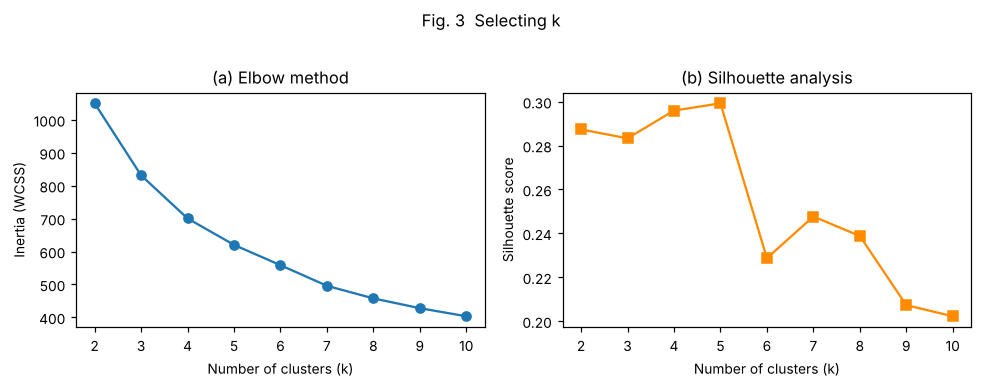

In [8]:
ks = list(range(2, 11)); inertia, sil, dbi = [], [], []
for k in ks:
    m = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RS).fit(X)
    inertia.append(m.inertia_); sil.append(silhouette_score(X, m.labels_)); dbi.append(davies_bouldin_score(X, m.labels_))

kres = pd.DataFrame({"k": ks, "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 4), "davies_bouldin": np.round(dbi, 3)})
display(kres)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_xlabel("Number of clusters (k)"); ax[0].set_ylabel("Inertia (WCSS)"); ax[0].set_title("(a) Elbow method")
ax[1].plot(ks, sil, "s-", color="darkorange"); ax[1].set_xlabel("Number of clusters (k)"); ax[1].set_ylabel("Silhouette score"); ax[1].set_title("(b) Silhouette analysis")
plt.suptitle("Fig. 3  Selecting k", y=1.02); plt.tight_layout(); plt.show()

**Decision:** there is no sharp elbow, and silhouette scores for k = 2 to 5 are nearly equal (0.283 to 0.299; k = 5 is marginally highest). We choose **k = 3** because it gives clearly interpretable groups (low / middle / high development) and is very similar to the k = 4 and k = 5 partitions (checked below). This is a judgement based partly on interpretability, not on the metrics alone.

In [9]:
K = 3
km = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=RS).fit(X)
df["kmeans"] = km.labels_
km_sil = silhouette_score(X, km.labels_); km_dbi = davies_bouldin_score(X, km.labels_)
print(f"K-means (k={K}): inertia = {km.inertia_:.1f}, silhouette = {km_sil:.4f}, Davies-Bouldin = {km_dbi:.3f}")

# Sensitivity to k and stability across random seeds
km4 = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=RS).fit(X)
km5 = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=RS).fit(X)
print("ARI k=3 vs k=4:", round(adjusted_rand_score(km.labels_, km4.labels_), 3))
print("ARI k=3 vs k=5:", round(adjusted_rand_score(km.labels_, km5.labels_), 3))
aris = [adjusted_rand_score(km.labels_, KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=s).fit(X).labels_) for s in range(1, 21)]
print("Minimum ARI over 20 different seeds:", round(min(aris), 3), "(1.0 = identical clusters)")

K-means (k=3): inertia = 831.4, silhouette = 0.2833, Davies-Bouldin = 1.277
ARI k=3 vs k=4: 0.932
ARI k=3 vs k=5: 0.905
Minimum ARI over 20 different seeds: 1.0 (1.0 = identical clusters)


## 7. DBSCAN

### 7.1 k-distance plot and parameter grid search
The 5th-nearest-neighbour distance plot helps choose `eps`. We then search `eps` from 0.8 to 3.0 and `min_samples` in {3, 4, 5, 6, 8, 10}. Silhouette is computed on non-noise points only.

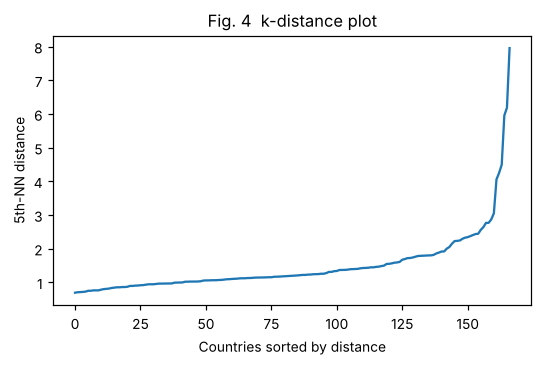

Configurations with >=2 clusters and zero noise: 0
Top 5 by silhouette (note the very high noise counts):


,eps,min_samples,clusters,noise,silhouette
10,0.9,8,2,148,0.6533
23,1.1,10,2,104,0.4631
29,1.2,10,2,94,0.4481
15,1.0,6,2,113,0.4443
22,1.1,8,2,97,0.4408


In [10]:
nn = NearestNeighbors(n_neighbors=5).fit(X); d, _ = nn.kneighbors(X); kd = np.sort(d[:, 4])
plt.figure(figsize=(5, 3.4)); plt.plot(kd)
plt.xlabel("Countries sorted by distance"); plt.ylabel("5th-NN distance"); plt.title("Fig. 4  k-distance plot"); plt.tight_layout(); plt.show()

grid = []
for eps in np.arange(0.8, 3.01, 0.1):
    for ms in [3, 4, 5, 6, 8, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        ncl = len(set(lab)) - (1 if -1 in lab else 0); noise = int((lab == -1).sum())
        s = silhouette_score(X[lab != -1], lab[lab != -1]) if ncl >= 2 else np.nan
        grid.append(dict(eps=round(eps, 1), min_samples=ms, clusters=ncl, noise=noise, silhouette=None if np.isnan(s) else round(s, 4)))
G = pd.DataFrame(grid)
print("Configurations with >=2 clusters and zero noise:", int(((G.noise == 0) & (G.clusters >= 2)).sum()))
print("Top 5 by silhouette (note the very high noise counts):")
display(G[G.clusters >= 2].sort_values("silhouette", ascending=False).head(5))

### 7.2 Final DBSCAN model
The highest-silhouette configurations label most countries as noise, which is not useful. We therefore choose the best silhouette among settings with at least 2 clusters and **at most 15% noise**. This constraint is our own modelling decision.

In [11]:
cand = G[(G.clusters >= 2) & (G.noise <= 0.15 * len(df))].sort_values("silhouette", ascending=False)
EPS, MS = float(cand.iloc[0].eps), int(cand.iloc[0].min_samples)
db = DBSCAN(eps=EPS, min_samples=MS).fit(X); df["dbscan"] = db.labels_
mask = db.labels_ != -1
db_sil = silhouette_score(X[mask], db.labels_[mask]); db_dbi = davies_bouldin_score(X[mask], db.labels_[mask])
print(f"DBSCAN: eps = {EPS}, min_samples = {MS}")
print("Cluster sizes (-1 = noise):", df.dbscan.value_counts().sort_index().to_dict())
print(f"Silhouette (non-noise only) = {db_sil:.4f}, Davies-Bouldin = {db_dbi:.3f}")
print("ARI K-means vs DBSCAN (non-noise points):", round(adjusted_rand_score(df.kmeans[mask], df.dbscan[mask]), 3))
print()
print("Noise countries:", ", ".join(df.loc[~mask, "country"]))
print("Countries in small DBSCAN cluster 1:", ", ".join(df.loc[df.dbscan == 1, "country"]))

DBSCAN: eps = 1.5, min_samples = 3
Cluster sizes (-1 = noise): {-1: 25, 0: 139, 1: 3}
Silhouette (non-noise only) = 0.2261, Davies-Bouldin = 0.950
ARI K-means vs DBSCAN (non-noise points): 0.01

Noise countries: Angola, Brunei, Central African Republic, Congo, Dem. Rep., Congo, Rep., Equatorial Guinea, Gabon, Haiti, Iraq, Kuwait, Lesotho, Luxembourg, Malta, Mongolia, Nigeria, Norway, Qatar, Rwanda, Seychelles, Sierra Leone, Singapore, Timor-Leste, Turkmenistan, United States, Venezuela
Countries in small DBSCAN cluster 1: Kiribati, Liberia, Micronesia, Fed. Sts.


## 8. Visualising the clusters with PCA
PCA to two components is used **only for plotting**; both algorithms were run on the full standardised data.

Explained variance ratio: [0.4595 0.1718]


,PC1,PC2
child_mort,-0.42,0.19
exports,0.28,0.61
health,0.15,-0.24
imports,0.16,0.67
income,0.40,0.02
inflation,-0.19,-0.01
life_expec,0.43,-0.22
total_fer,-0.40,0.16
gdpp,0.39,-0.05


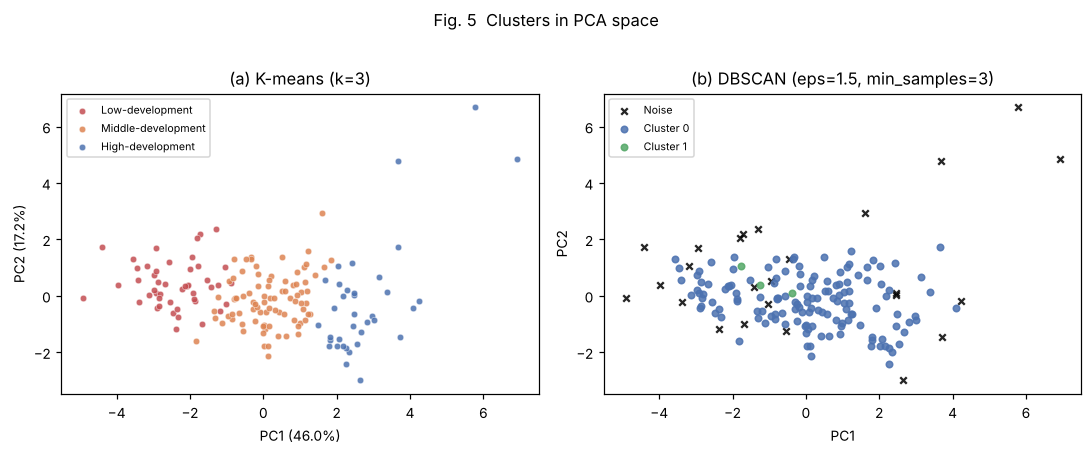

In [12]:
pca = PCA(n_components=2, random_state=RS); P = pca.fit_transform(X)
print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 4))
display(pd.DataFrame(pca.components_.T, index=feats, columns=["PC1", "PC2"]).round(2))

# Name K-means clusters by child mortality (highest = least developed). Names are our own interpretive labels.
order = df.groupby("kmeans")["child_mort"].mean().sort_values(ascending=False).index.tolist()
names = {order[0]: "Low-development", order[1]: "Middle-development", order[2]: "High-development"}
df["km_name"] = df.kmeans.map(names)

cols = {"Low-development": "#C44E52", "Middle-development": "#DD8452", "High-development": "#4C72B0"}
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for n, c in cols.items():
    m = df.km_name == n
    ax[0].scatter(P[m, 0], P[m, 1], s=18, c=c, label=n, alpha=.85, edgecolor="white", linewidth=.3)
ax[0].set_title("(a) K-means (k=3)"); ax[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"); ax[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"); ax[0].legend(fontsize=7)
pal = {-1: "black", 0: "#4C72B0", 1: "#55A868", 2: "#C44E52", 3: "#8172B2"}
for l in sorted(set(db.labels_)):
    m = db.labels_ == l
    ax[1].scatter(P[m, 0], P[m, 1], s=18, c=pal.get(l, "grey"), marker="o" if l != -1 else "x", label="Noise" if l == -1 else f"Cluster {l}", alpha=.85)
ax[1].set_title(f"(b) DBSCAN (eps={EPS}, min_samples={MS})"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].legend(fontsize=7)
plt.suptitle("Fig. 5  Clusters in PCA space", y=1.02); plt.tight_layout(); plt.show()

## 9. Cluster profiles (K-means)

km_name,Low-development,Middle-development,High-development
n_countries,47.00,84.00,36.00
child_mort,92.96,21.93,5.00
exports,29.15,40.24,58.74
health,6.39,6.20,8.81
imports,42.32,47.47,51.49
income,3942.40,12305.60,45672.22
inflation,12.02,7.60,2.67
life_expec,59.19,72.81,80.13
total_fer,5.01,2.31,1.75
gdpp,1922.38,6486.45,42494.44


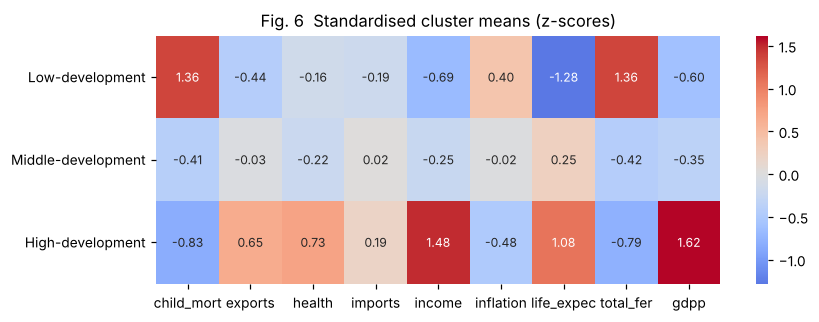

Low-development: Burundi, Liberia, Congo, Dem. Rep., Niger, Sierra Leone, Madagascar, Mozambique, Central African Republic ...
Middle-development: Nepal, Tajikistan, Bangladesh, Cambodia, Kyrgyz Republic, Myanmar, Solomon Islands, Vietnam ...
High-development: Slovak Republic, Czech Republic, Bahrain, Malta, South Korea, Portugal, Slovenia, Greece ...

South Asia:


,country,km_name,dbscan
12,Bangladesh,Middle-development,0
18,Bhutan,Middle-development,0
69,India,Middle-development,0
109,Nepal,Middle-development,0
116,Pakistan,Low-development,0
140,Sri Lanka,Middle-development,0


In [13]:
order_names = ["Low-development", "Middle-development", "High-development"]
profile = df.groupby("km_name")[feats].mean().round(2).loc[order_names]
profile.insert(0, "n_countries", df.km_name.value_counts().loc[order_names])
display(profile.T)

z = pd.DataFrame(X, columns=feats).groupby(df.km_name.values).mean().loc[order_names]
plt.figure(figsize=(8, 3))
sns.heatmap(z, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Fig. 6  Standardised cluster means (z-scores)"); plt.ylabel(""); plt.tight_layout(); plt.show()

for n in order_names:
    print(f"{n}: {', '.join(df[df.km_name == n].sort_values('gdpp')['country'].head(8))} ...")
print()
print("South Asia:")
display(df[df.country.isin(["Bangladesh", "India", "Pakistan", "Nepal", "Sri Lanka", "Bhutan"])][["country", "km_name", "dbscan"]])

## 10. Comparison and saving results

In [14]:
comparison = pd.DataFrame({
    "K-means (k=3)": {"Clusters": 3, "Noise points": 0, "Silhouette": round(km_sil, 3), "Davies-Bouldin": round(km_dbi, 3)},
    f"DBSCAN (eps={EPS}, min_samples={MS})": {"Clusters": int(len(set(db.labels_)) - 1), "Noise points": int((~mask).sum()),
                                              "Silhouette": round(db_sil, 3) , "Davies-Bouldin": round(db_dbi, 3)}})
display(comparison)
print("Cross-tabulation of K-means groups vs DBSCAN labels (-1 = noise):")
display(pd.crosstab(df.km_name, df.dbscan))

df[["country", "kmeans", "km_name", "dbscan"]].to_csv("country_clusters.csv", index=False)
print("Saved country_clusters.csv")
# In Colab you can download it with:  from google.colab import files; files.download("country_clusters.csv")

,K-means (k=3),"DBSCAN (eps=1.5, min_samples=3)"
Clusters,3.000,2.000
Noise points,0.000,25.000
Silhouette,0.283,0.226
Davies-Bouldin,1.277,0.950


Cross-tabulation of K-means groups vs DBSCAN labels (-1 = noise):


dbscan,-1,0,1
km_name,,,
High-development,8,28,0
Low-development,13,32,2
Middle-development,4,79,1


Saved country_clusters.csv


## 11. Conclusion
- **K-means (k = 3)** gave interpretable low-, middle- and high-development groups (47, 84 and 36 countries; silhouette 0.283), separated mainly by child mortality, fertility, life expectancy, income and GDP per capita.
- **DBSCAN** found one dominant cluster of 139 countries, a tiny cluster of 3, and 25 noise points (silhouette 0.226 on non-noise points only), so it works better for spotting extreme countries than for defining development tiers.
- Both silhouette scores are modest, so the groups should be read as segments of a **continuum**, not sharp categories.
- **Limitations:** small dataset (167 countries), unstated data year, skewed and correlated indicators, partly subjective choice of k, and no external validation.
- **Future work:** hierarchical or Gaussian-mixture clustering, log-transform or robust scaling, comparison with an official classification (e.g. HDI), and multi-year data.